# Sample overview:

Describes the proof-of-concept sample built by `scripts/extract_sample.py`. Figures are saved into the sample's folder next to `sample.csv` and `config.yaml`.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

SAMPLE_DIR = Path('../data/processed/sample_n100')
s = pd.read_csv(SAMPLE_DIR / 'sample.csv')
s.shape

(100, 47)

In [2]:
BINS = ['0-0.25', '0.25-0.5', '0.5-0.75', '0.75-1']
COLORS = dict(zip(BINS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']))
SURFACE, INK, INK2, MUTED, GRID, BASE = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
plt.rcParams.update({
    'font.family': ['Helvetica Neue', 'Arial', 'sans-serif'], 'font.size': 11, 'figure.dpi': 120,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': BASE, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'xtick.major.size': 0, 'ytick.major.size': 0, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'legend.frameon': False,
})

def title(ax, text, sub=None):
    ax.set_title(text, loc='left', color=INK, fontsize=13, fontweight='bold', pad=22 if sub else 12)
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, color=INK2, fontsize=9.5)

## Human toxicity scores

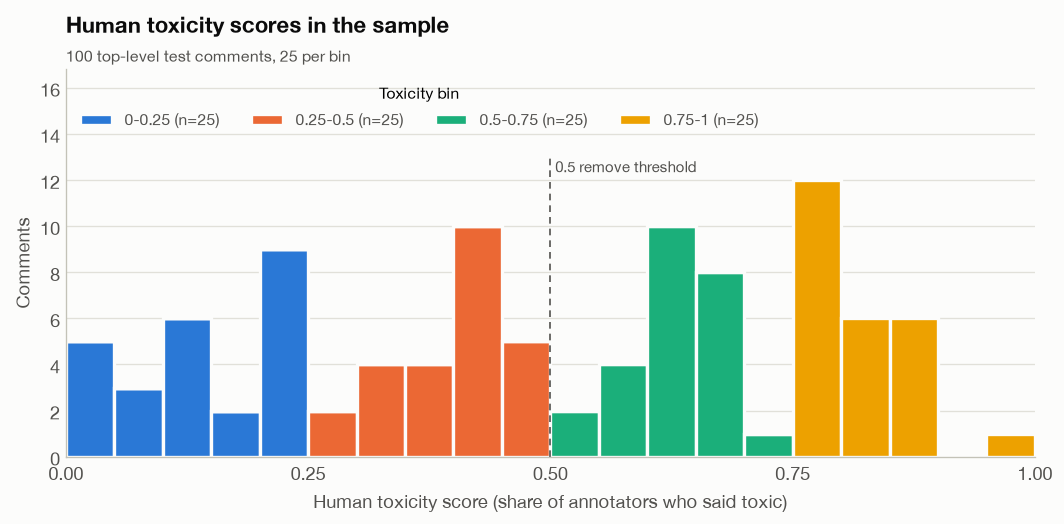

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
edges = np.arange(0, 1.0001, 0.05)
bottom = np.zeros(len(edges) - 1)
for b in BINS:
    h, _ = np.histogram(s.loc[s.toxicity_bin == b, 'toxicity'], bins=edges)
    ax.bar(edges[:-1], h, width=0.05, align='edge', bottom=bottom, color=COLORS[b],
           edgecolor=SURFACE, linewidth=2, label=f'{b} (n={(s.toxicity_bin == b).sum()})')
    bottom += h
top = bottom.max()
ax.vlines(0.5, 0, top * 1.08, color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(0.505, top * 1.08, '0.5 remove threshold', color=INK2, fontsize=9, va='top')
ax.set_ylim(0, top * 1.4); ax.set_xlim(0, 1); ax.set_xticks(np.arange(0, 1.01, 0.25))
ax.set_xlabel('Human toxicity score (share of annotators who said toxic)')
ax.set_ylabel('Comments')
ax.legend(title='Toxicity bin', title_fontsize=9.5, fontsize=9.5, loc='upper left', ncols=4, labelcolor=INK2)
title(ax, 'Human toxicity scores in the sample', '100 top-level test comments, 25 per bin')
fig.tight_layout()
fig.savefig(SAMPLE_DIR / 'toxicity_scores.png', dpi=200)
plt.show()

## Annotators per comment

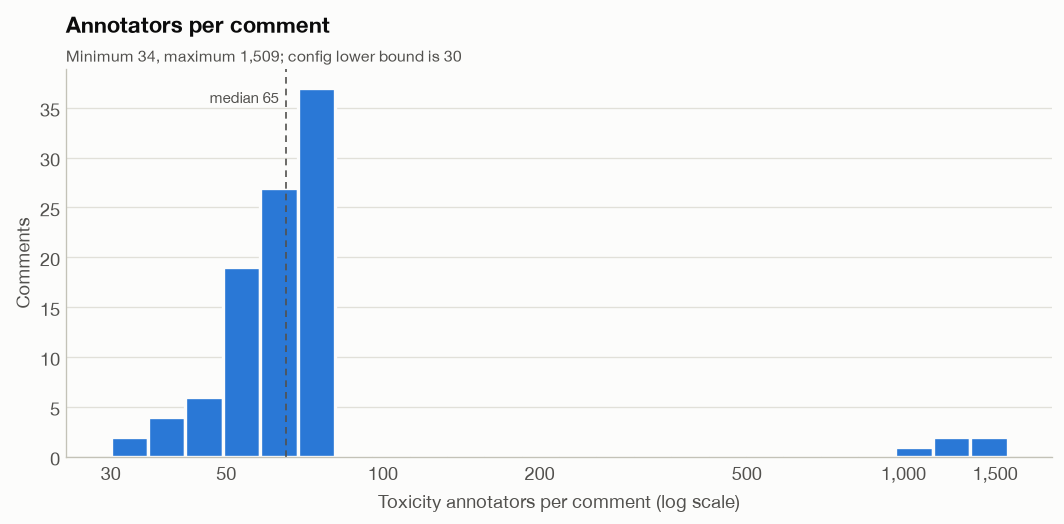

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
counts = s.toxicity_annotator_count
log_edges = np.logspace(np.log10(30), np.log10(counts.max() * 1.05), 25)
ax.hist(counts, bins=log_edges, color='#2a78d6', edgecolor=SURFACE, linewidth=2)
ax.set_xscale('log')
ax.set_xticks([30, 50, 100, 200, 500, 1000, 1500])
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.tick_params(which='minor', length=0)
med = counts.median()
ax.axvline(med, color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(med * 0.97, ax.get_ylim()[1] * 0.95, f'median {med:.0f}', color=INK2, fontsize=9, va='top', ha='right')
ax.set_xlabel('Toxicity annotators per comment (log scale)')
ax.set_ylabel('Comments')
title(ax, 'Annotators per comment', f'Minimum {counts.min()}, maximum {counts.max():,}; config lower bound is 30')
fig.tight_layout()
fig.savefig(SAMPLE_DIR / 'annotator_counts.png', dpi=200)
plt.show()

## Comment length

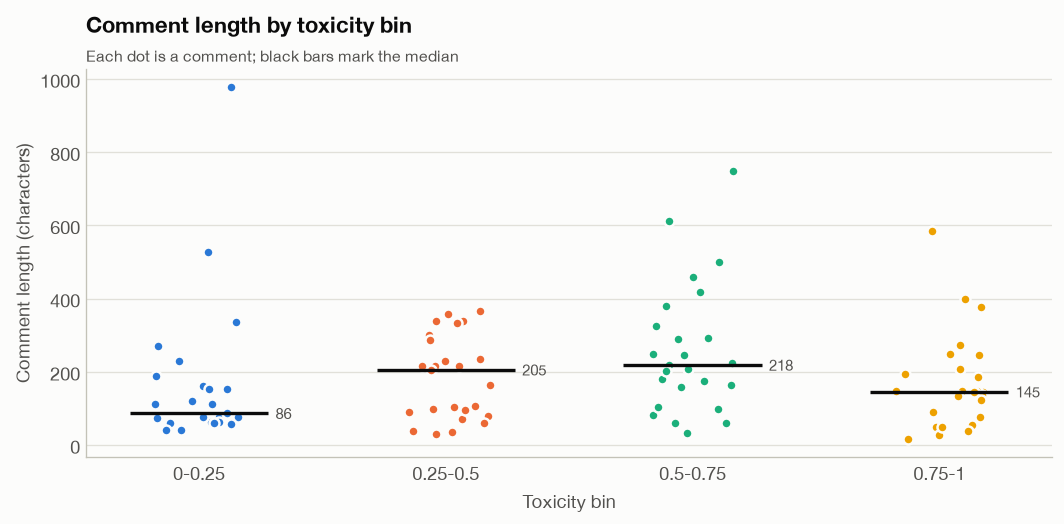

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
lengths = s.comment_text.str.len()
rng = np.random.default_rng(0)
for i, b in enumerate(BINS):
    y = lengths[s.toxicity_bin == b]
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(y)), y, s=36, color=COLORS[b],
               edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.hlines(y.median(), i - 0.28, i + 0.28, color=INK, lw=2, zorder=4)
    ax.text(i + 0.31, y.median(), f'{y.median():.0f}', color=INK2, fontsize=9, va='center')
ax.set_xticks(range(len(BINS)), BINS)
ax.set_xlabel('Toxicity bin')
ax.set_ylabel('Comment length (characters)')
title(ax, 'Comment length by toxicity bin', 'Each dot is a comment; black bars mark the median')
fig.tight_layout()
fig.savefig(SAMPLE_DIR / 'comment_length.png', dpi=200)
plt.show()

## Toxicity subtypes

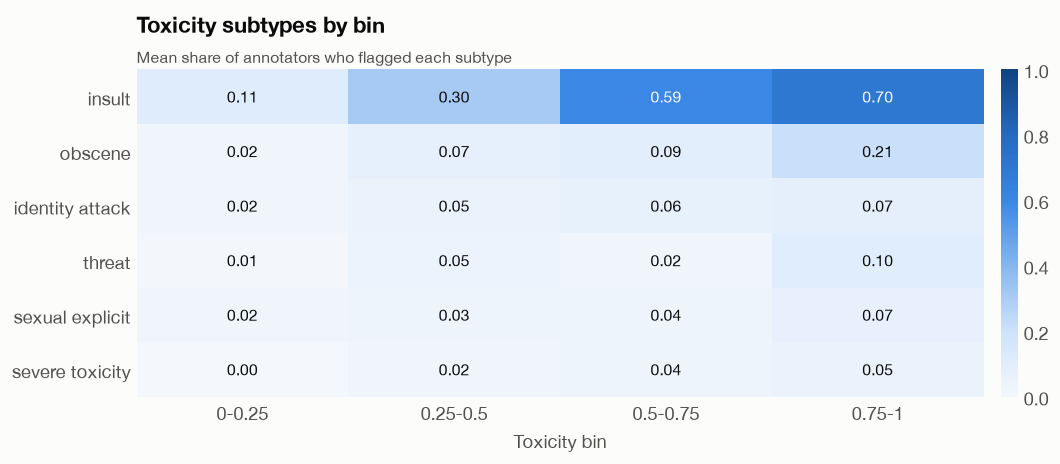

In [6]:
subtypes = ['insult', 'obscene', 'identity_attack', 'threat', 'sexual_explicit', 'severe_toxicity']
means = s.groupby('toxicity_bin')[subtypes].mean().reindex(BINS)

fig, ax = plt.subplots(figsize=(9, 4))
cmap = matplotlib.colors.LinearSegmentedColormap.from_list(
    'blue', ['#f4f8fd', '#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#104281'])
im = ax.imshow(means.T.values, cmap=cmap, vmin=0, vmax=1, aspect='auto')
for (j, i), v in np.ndenumerate(means.T.values):
    ax.text(i, j, f'{v:.2f}', ha='center', va='center', fontsize=9.5, color='#ffffff' if v > 0.45 else INK)
ax.set_xticks(range(len(BINS)), BINS)
ax.set_yticks(range(len(subtypes)), [t.replace('_', ' ') for t in subtypes])
ax.set_xlabel('Toxicity bin')
ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cb.outline.set_visible(False); cb.ax.tick_params(length=0, labelcolor=INK2)
title(ax, 'Toxicity subtypes by bin', 'Mean share of annotators who flagged each subtype')
fig.tight_layout()
fig.savefig(SAMPLE_DIR / 'subtype_heatmap.png', dpi=200)
plt.show()